# LDA Topic Modelling by Primary Category

This notebook performs topic modelling using Latent Dirichlet Allocation (LDA) on arXiv abstracts.

## Objectives
- Load the cleaned arXiv dataset
- Perform basic exploratory data analysis (EDA)
- Filter data for one selected primary category
- Apply shared preprocessing from `lda_nmf_preprocessing.py`
- Explore unigrams, bigrams, and trigrams
- Train LDA models with different topic numbers
- Evaluate topic quality using coherence score
- Inspect the learned topics

In [40]:
# Uncomment and run if needed

# !pip install pandas numpy matplotlib
# !pip install nltk gensim scikit-learn

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

import gensim
from gensim.corpora import Dictionary
from gensim.models import CoherenceModel
from gensim.models.phrases import Phrases, Phraser
from gensim.models.ldamodel import LdaModel

## Load Dataset

We first load the cleaned arXiv metadata file and inspect its structure.

In [42]:
# load dataset
df = pd.read_csv("../data/arxiv_cleaned_metadata.csv")

print(df.shape)
df.head()

(19973, 17)


,id,title,abstract,published,updated,authors,primary_category,all_categories,queried_category,broad_subject,title_clean,abstract_clean,text,abstract_word_count,title_word_count,base_id,version
0,http://arxiv.org/abs/0704.1169v1,Holographic bound and protein linguistics,The holographic bound in physics constrains th...,2007-04-10T12:04:28Z,2007-04-10T12:04:28Z,"Dirson Jian Li, Shengli Zhang",q-bio.GN,"q-bio.GN, hep-th, q-bio.QM",q-bio.GN,biology,holographic bound and protein linguistics,the holographic bound in physics constrains th...,holographic bound and protein linguistics the ...,66,5,704.1169,1.0
1,http://arxiv.org/abs/0704.2191v2,Mismatch Repair Error Implies Chargaff's Secon...,Chargaff's second parity rule holds empiricall...,2007-04-17T16:15:37Z,2007-09-20T15:46:34Z,Bo Deng,q-bio.GN,q-bio.GN,q-bio.GN,biology,mismatch repair error implies chargaff's secon...,chargaff's second parity rule holds empiricall...,mismatch repair error implies chargaff's secon...,155,8,704.2191,2.0
2,http://arxiv.org/abs/0704.3826v2,Non-coding DNA programs express adaptation and...,Significant fraction (98.5% in humans) of most...,2007-04-29T05:32:50Z,2007-08-02T16:23:54Z,Mark Ya. Azbel,q-bio.GN,"q-bio.GN, cond-mat.other, nlin.AO, q-bio.OT, q...",q-bio.GN,biology,non-coding dna programs express adaptation and...,significant fraction (98.5% in humans) of most...,non-coding dna programs express adaptation and...,161,9,704.3826,2.0
3,http://arxiv.org/abs/0705.1656v1,Chromatin Folding in Relation to Human Genome ...,Three-dimensional (3D) chromatin structure is ...,2007-05-11T14:12:05Z,2007-05-11T14:12:05Z,"Julio Mateos-Langerak, Osdilly Giromus, Wim de...",q-bio.GN,q-bio.GN,q-bio.GN,biology,chromatin folding in relation to human genome ...,three-dimensional (3d) chromatin structure is ...,chromatin folding in relation to human genome ...,226,8,705.1656,1.0
4,http://arxiv.org/abs/0705.2143v1,Inverted and mirror repeats in model nucleotid...,We analytically and numerically study the prob...,2007-05-15T13:37:17Z,2007-05-15T13:37:17Z,"Fabrizio Lillo, Marco Spanó",q-bio.GN,"q-bio.GN, q-bio.QM",q-bio.GN,biology,inverted and mirror repeats in model nucleotid...,we analytically and numerically study the prob...,inverted and mirror repeats in model nucleotid...,79,8,705.2143,1.0


In [43]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Shape: (19973, 17)

Columns:
['id', 'title', 'abstract', 'published', 'updated', 'authors', 'primary_category', 'all_categories', 'queried_category', 'broad_subject', 'title_clean', 'abstract_clean', 'text', 'abstract_word_count', 'title_word_count', 'base_id', 'version']


## Basic EDA

We check for missing values, category distribution, and abstract length to understand the dataset before topic modelling.

count    19973.000000
mean       165.876834
std         50.715755
min         20.000000
25%        130.000000
50%        162.000000
75%        200.000000
max        539.000000
Name: abstract_word_count, dtype: float64


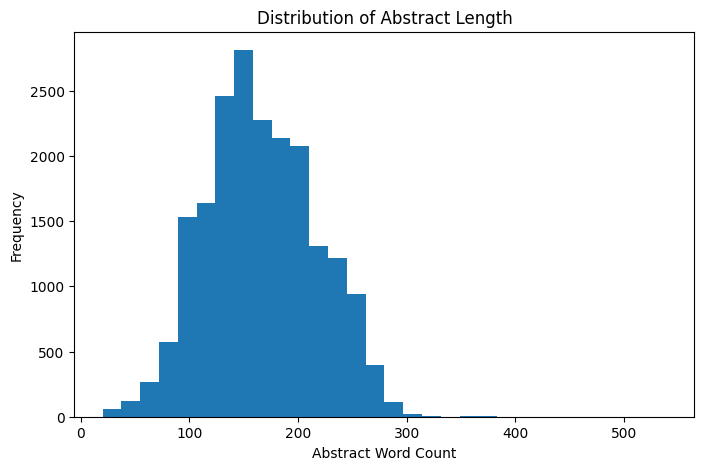

In [44]:
df["abstract_word_count"] = df["abstract"].fillna("").apply(lambda x: len(str(x).split()))

print(df["abstract_word_count"].describe())

plt.figure(figsize=(8, 5))
plt.hist(df["abstract_word_count"], bins=30)
plt.xlabel("Abstract Word Count")
plt.ylabel("Frequency")
plt.title("Distribution of Abstract Length")
plt.show()

## Apply Shared Preprocessing to All Abstracts

The same base preprocessing is applied to all documents to ensure consistency across later topic models. This shared preprocessing includes text cleaning, tokenization, stopword removal, and lemmatization.

At this stage, only general preprocessing is applied. Phrase modelling such as bigrams and trigrams will be performed later within each primary category, since meaningful phrases may differ across categories.

In [45]:
import lda_nmf_preprocessing

df["tokens_clean"] = df["text"].apply(
    lambda x: lda_nmf_preprocessing.preprocess_text(x)
)

In [46]:
df[["text", "tokens_clean"]].head(20)

,text,tokens_clean
0,holographic bound and protein linguistics the ...,"[holographic, bound, protein, linguistics, hol..."
1,mismatch repair error implies chargaff's secon...,"[mismatch, repair, error, implies, chargaff, s..."
2,non-coding dna programs express adaptation and...,"[non-coding, dna, program, express, adaptation..."
3,chromatin folding in relation to human genome ...,"[chromatin, folding, relation, human, genome, ..."
4,inverted and mirror repeats in model nucleotid...,"[inverted, mirror, repeat, model, nucleotide, ..."
5,towards understanding the origin of genetic la...,"[towards, understanding, origin, genetic, lang..."
6,reciprocal best hits are not a logically suffi...,"[reciprocal, best, hit, logically, sufficient,..."
7,codon usage bias measured through entropy appr...,"[codon, usage, bias, measured, entropy, approa..."
8,universal power law behaviors in genomic seque...,"[universal, power, law, behavior, genomic, seq..."
9,orfmapper: a web-based application for visuali...,"[orfmapper, web-based, application, visualizin..."


## Inspect Frequent Terms After Preprocessing

We inspect the most common terms after preprocessing to identify whether additional custom stopwords may be required. If the most frequent terms are overly generic academic words, they may later be added to the stopword list.

In [47]:
all_words = [word for doc in df["tokens_clean"] for word in doc]
word_freq = Counter(all_words)

word_freq.most_common(30)

[('model', 26684),
 ('data', 13470),
 ('method', 13277),
 ('system', 11261),
 ('using', 10189),
 ('approach', 9276),
 ('result', 9210),
 ('network', 9142),
 ('framework', 8298),
 ('study', 8290),
 ('learning', 8107),
 ('performance', 7912),
 ('analysis', 7362),
 ('show', 6797),
 ('paper', 6695),
 ('dynamic', 6180),
 ('information', 5887),
 ('proposed', 5758),
 ('protein', 5633),
 ('structure', 5438),
 ('based', 5414),
 ('neural', 5345),
 ('across', 5322),
 ('effect', 5091),
 ('speech', 5039),
 ('propose', 4940),
 ('control', 4935),
 ('design', 4880),
 ('two', 4827),
 ('time', 4752)]

In [48]:
extra_stopwords = [
    "model", "data", "method", "approach", "result",
    "study", "paper", "using", "based", "proposed",
    "show", "system", "framework", "analysis",
    "performance"
]

df["tokens_clean"] = df["text"].apply(
    lambda x: lda_nmf_preprocessing.preprocess_text(
        x,
        extra_stopwords=extra_stopwords
    )
)

In [49]:
df[["text", "tokens_clean"]].head(20)

,text,tokens_clean
0,holographic bound and protein linguistics the ...,"[holographic, bound, protein, linguistics, hol..."
1,mismatch repair error implies chargaff's secon...,"[mismatch, repair, error, implies, chargaff, s..."
2,non-coding dna programs express adaptation and...,"[non-coding, dna, program, express, adaptation..."
3,chromatin folding in relation to human genome ...,"[chromatin, folding, relation, human, genome, ..."
4,inverted and mirror repeats in model nucleotid...,"[inverted, mirror, repeat, nucleotide, sequenc..."
5,towards understanding the origin of genetic la...,"[towards, understanding, origin, genetic, lang..."
6,reciprocal best hits are not a logically suffi...,"[reciprocal, best, hit, logically, sufficient,..."
7,codon usage bias measured through entropy appr...,"[codon, usage, bias, measured, entropy, codon,..."
8,universal power law behaviors in genomic seque...,"[universal, power, law, behavior, genomic, seq..."
9,orfmapper: a web-based application for visuali...,"[orfmapper, web-based, application, visualizin..."


## Select One Primary Category for Topic Modelling

Topic modelling is performed separately for each primary category. Therefore, after shared preprocessing has been completed on the full dataset, we isolate one category and build a category-specific LDA model.

This design allows the discovered topics to reflect sub-themes within a category rather than broad differences between categories.

In [50]:
selected_category = "econ.EM"   # change this as needed

cat_df = df[df["primary_category"] == selected_category].copy()
cat_docs = cat_df["tokens_clean"].tolist()

print("Selected category:", selected_category)
print("Number of documents:", len(cat_docs))

Selected category: econ.EM
Number of documents: 2000


## Build Category-Specific Bigrams and Trigrams

Phrase modelling is performed separately within the selected category. This is because meaningful multi-word expressions may vary across different research domains.

For example, a phrase such as `neural_network` may be important in one category, while another category may contain different characteristic phrases.

We therefore explore:
- unigrams only
- unigrams + bigrams
- unigrams + bigrams + trigrams

In [51]:
print(type(cat_docs))
print(type(cat_docs[0]))
print(cat_docs[0])

<class 'list'>
<class 'list'>
['economic', 'activity', 'climate', 'change', 'survey', 'recent', 'econometric', 'contribution', 'measure', 'relationship', 'economic', 'activity', 'climate', 'change', 'due', 'critical', 'relevance', 'effect', 'well-being', 'future', 'generation', 'explosion', 'publication', 'devoted', 'measuring', 'relationship', 'main', 'channel', 'relation', 'economic', 'activity', 'climate', 'change', 'complex', 'possibility', 'causality', 'running', 'direction', 'starting', 'economic', 'activity', 'channel', 'relate', 'economic', 'activity', 'climate', 'change', 'energy', 'consumption', 'consequent', 'pollution', 'hence', 'first', 'describe', 'main', 'econometric', 'contribution', 'interaction', 'economic', 'activity', 'energy', 'consumption', 'moving', 'describing', 'contribution', 'interaction', 'economic', 'activity', 'pollution', 'finally', 'look', 'main', 'result', 'relationship', 'climate', 'change', 'economic', 'activity', 'important', 'consequence', 'climate'

In [52]:
bigram_phrases = Phrases(cat_docs, min_count=5, threshold=10)
bigram_model = Phraser(bigram_phrases)

docs_bigram = [bigram_model[doc] for doc in cat_docs]

trigram_phrases = Phrases(docs_bigram, min_count=5, threshold=10)
trigram_model = Phraser(trigram_phrases)

docs_trigram = [trigram_model[doc] for doc in docs_bigram]

In [53]:
print("Original tokens:")
print(cat_docs[0][:30])

print("\nWith bigrams:")
print(docs_bigram[0][:30])

print("\nWith trigrams:")
print(docs_trigram[0][:30])

Original tokens:
['economic', 'activity', 'climate', 'change', 'survey', 'recent', 'econometric', 'contribution', 'measure', 'relationship', 'economic', 'activity', 'climate', 'change', 'due', 'critical', 'relevance', 'effect', 'well-being', 'future', 'generation', 'explosion', 'publication', 'devoted', 'measuring', 'relationship', 'main', 'channel', 'relation', 'economic']

With bigrams:
['economic_activity', 'climate_change', 'survey', 'recent', 'econometric', 'contribution', 'measure', 'relationship', 'economic_activity', 'climate_change', 'due', 'critical', 'relevance', 'effect', 'well-being', 'future', 'generation', 'explosion', 'publication', 'devoted', 'measuring', 'relationship', 'main', 'channel', 'relation', 'economic_activity', 'climate_change', 'complex', 'possibility', 'causality']

With trigrams:
['economic_activity', 'climate_change', 'survey', 'recent', 'econometric', 'contribution', 'measure', 'relationship', 'economic_activity', 'climate_change', 'due', 'critical', 'r

In [54]:
bigram_tokens = [token for doc in docs_bigram for token in doc if "_" in token]
trigram_tokens = [token for doc in docs_trigram for token in doc if token.count("_") >= 2]

print("Top bigrams:")
print(Counter(bigram_tokens).most_common(20))

print("\nTop trigrams:")
print(Counter(trigram_tokens).most_common(20))

Top bigrams:
[('treatment_effect', 480), ('machine_learning', 300), ('monte_carlo', 252), ('time_series', 244), ('instrumental_variable', 192), ('empirical_application', 179), ('finite_sample', 160), ('fixed_effect', 144), ('causal_effect', 144), ('average_treatment', 137), ('causal_inference', 127), ('confidence_interval', 116), ('estimation_inference', 101), ('sample_size', 96), ('synthetic_control', 96), ('potential_outcome', 95), ('test_statistic', 88), ('impulse_response', 85), ('standard_error', 78), ('unobserved_heterogeneity', 78)]

Top trigrams:
[('average_treatment_effect', 87), ('heterogeneous_treatment_effect', 63), ('regression_discontinuity_design', 46), ('local_average_treatment_effect', 43), ('two-way_fixed_effect', 38), ('simulation_empirical_application', 35), ('average_treatment_effect_treated', 33), ('machine_learning_model', 32), ('treatment_effect_heterogeneity', 30), ('double_machine_learning', 30), ('two_empirical_application', 29), ('consistent_asymptotically_n

## Choose the Text Representation for LDA

LDA can be trained using different document representations. In this notebook, we compare phrase modelling choices and then select one final representation for the topic model.

For scientific abstracts, bigrams often improve topic interpretability, while trigrams may provide additional value only when meaningful three-word terms are common.

In [55]:
lda_docs = docs_bigram   # can switch to cat_docs or docs_trigram

## Create the Gensim Dictionary and Bag-of-Words Corpus

Gensim LDA requires:
- a dictionary that maps each token to an integer id
- a bag-of-words corpus that represents each document as token counts

Very rare words and overly common words are filtered out to reduce noise and improve topic quality.

In [56]:
dictionary = Dictionary(lda_docs)
dictionary.filter_extremes(no_below=5, no_above=0.5)

corpus = [dictionary.doc2bow(doc) for doc in lda_docs]

In [57]:
print("Dictionary size:", len(dictionary))
print("Sample document BoW:", corpus[0][:10])

Dictionary size: 4345
Sample document BoW: [(0, 1), (1, 1), (2, 2), (3, 1), (4, 6), (5, 1), (6, 1), (7, 4), (8, 1), (9, 1)]


## Train and Evaluate LDA Models

LDA requires the number of topics to be specified in advance. To identify a suitable value, multiple models are trained with different topic numbers and evaluated using coherence score.

Coherence measures how semantically related the top words within a topic are. Higher coherence generally indicates more interpretable topics.

In [58]:
def compute_coherence_values(corpus, dictionary, texts, topic_range):
    results = []

    for num_topics in topic_range:
        lda_model = LdaModel(
            corpus=corpus,
            id2word=dictionary,
            num_topics=num_topics,
            random_state=42,
            chunksize=100,
            passes=10,
            alpha="auto"
        )

        coherence_model = CoherenceModel(
            model=lda_model,
            texts=texts,
            dictionary=dictionary,
            coherence="c_v"
        )

        coherence_score = coherence_model.get_coherence()

        results.append({
            "num_topics": num_topics,
            "model": lda_model,
            "coherence": coherence_score
        })

        print(f"num_topics={num_topics}, coherence={coherence_score:.4f}")

    return results

In [59]:
topic_range = range(2, 11)

results = compute_coherence_values(
    corpus=corpus,
    dictionary=dictionary,
    texts=lda_docs,
    topic_range=topic_range
)

num_topics=2, coherence=0.3295
num_topics=3, coherence=0.3531
num_topics=4, coherence=0.3847
num_topics=5, coherence=0.3779
num_topics=6, coherence=0.3859
num_topics=7, coherence=0.3594
num_topics=8, coherence=0.3799
num_topics=9, coherence=0.3488
num_topics=10, coherence=0.3607


In [60]:
results_df = pd.DataFrame([
    {"num_topics": r["num_topics"], "coherence": r["coherence"]}
    for r in results
])

results_df

,num_topics,coherence
0,2,0.329520
1,3,0.353080
2,4,0.384681
3,5,0.377914
4,6,0.385930
5,7,0.359364
6,8,0.379937
7,9,0.348807
8,10,0.360693


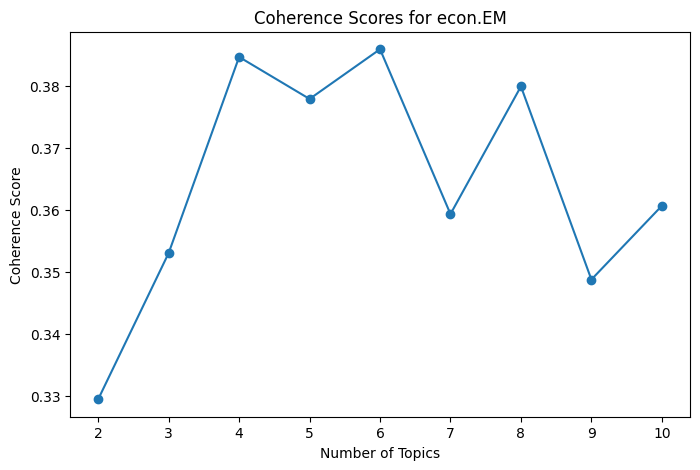

In [61]:
plt.figure(figsize=(8, 5))
plt.plot(results_df["num_topics"], results_df["coherence"], marker="o")
plt.xlabel("Number of Topics")
plt.ylabel("Coherence Score")
plt.title(f"Coherence Scores for {selected_category}")
plt.xticks(results_df["num_topics"])
plt.show()

## Select the Best LDA Model

The model with the highest coherence score is selected as the best candidate. However, coherence alone is not sufficient, so manual inspection of topic meaning is also necessary.

In [62]:
best_result = max(results, key=lambda x: x["coherence"])
best_lda_model = best_result["model"]

print("Best number of topics:", best_result["num_topics"])
print("Best coherence:", round(best_result["coherence"], 4))

Best number of topics: 6
Best coherence: 0.3859


## Inspect Learned Topics

The top words for each topic are printed to evaluate whether the topics are meaningful, interpretable, and distinct from one another.

In [63]:
for topic_id, topic_words in best_lda_model.print_topics(num_words=10):
    print(f"Topic {topic_id}: {topic_words}")
    print()

Topic 0: 0.029*"structural" + 0.021*"algorithm" + 0.016*"product" + 0.015*"indicator" + 0.012*"shock" + 0.011*"equation" + 0.010*"proxy" + 0.010*"restriction" + 0.010*"identification" + 0.010*"region"

Topic 1: 0.023*"test" + 0.015*"model" + 0.011*"factor" + 0.009*"forecast" + 0.008*"variable" + 0.008*"regression" + 0.008*"method" + 0.008*"error" + 0.007*"forecasting" + 0.007*"testing"

Topic 2: 0.020*"effect" + 0.012*"outcome" + 0.011*"treatment" + 0.011*"treatment_effect" + 0.010*"assumption" + 0.010*"estimate" + 0.009*"setting" + 0.009*"policy" + 0.008*"design" + 0.007*"identification"

Topic 3: 0.017*"dynamic" + 0.015*"market" + 0.015*"price" + 0.013*"risk" + 0.012*"economic" + 0.009*"financial" + 0.009*"volatility" + 0.009*"index" + 0.009*"spatial" + 0.008*"firm"

Topic 4: 0.029*"model" + 0.027*"estimation" + 0.018*"distribution" + 0.017*"parameter" + 0.016*"function" + 0.013*"inference" + 0.011*"estimator" + 0.008*"bayesian" + 0.008*"process" + 0.008*"nonparametric"

Topic 5: 0.0

Initial topic modelling results revealed that many topics were dominated by generic methodological terms such as “model”, “estimation”, and “method”. To improve interpretability, additional domain-specific stopwords were introduced to reduce the influence of generic academic vocabulary. This resulted in more distinct and meaningful topics representing underlying economic themes.

In [64]:
extra_stopwords = [
    "model", "method", "estimation", "estimator",
    "paper", "approach", "result", "test", "using",
    "new", "based", "inference", "data", "study", 
    "proposed", "show", "system", "framework", "analysis",
    "performance"
]

df["tokens_clean"] = df["text"].apply(
    lambda x: lda_nmf_preprocessing.preprocess_text(
        x,
        extra_stopwords=extra_stopwords
    )
)

selected_category = "econ.EM"   # change this as needed

cat_df = df[df["primary_category"] == selected_category].copy()
cat_docs = cat_df["tokens_clean"].tolist()

bigram_phrases = Phrases(cat_docs, min_count=5, threshold=10)
bigram_model = Phraser(bigram_phrases)

docs_bigram = [bigram_model[doc] for doc in cat_docs]

trigram_phrases = Phrases(docs_bigram, min_count=5, threshold=10)
trigram_model = Phraser(trigram_phrases)

docs_trigram = [trigram_model[doc] for doc in docs_bigram]
bigram_tokens = [token for doc in docs_bigram for token in doc if "_" in token]
trigram_tokens = [token for doc in docs_trigram for token in doc if token.count("_") >= 2]

lda_docs = docs_bigram

dictionary = Dictionary(lda_docs)
dictionary.filter_extremes(no_below=5, no_above=0.5)

corpus = [dictionary.doc2bow(doc) for doc in lda_docs]

refined_lda_model = LdaModel(
    corpus=corpus,
    id2word=dictionary,
    num_topics=6,
    random_state=42,
    chunksize=100,
    passes=10,
    alpha="auto",
    per_word_topics=True
)

for topic_id, topic_words in refined_lda_model.print_topics(num_words=10):
    print(f"Topic {topic_id}: {topic_words}")
    print()

Topic 0: 0.018*"model" + 0.018*"dynamic" + 0.012*"forecast" + 0.012*"forecasting" + 0.010*"economic" + 0.008*"shock" + 0.008*"prediction" + 0.007*"bayesian" + 0.007*"volatility" + 0.007*"index"

Topic 1: 0.054*"effect" + 0.018*"heterogeneity" + 0.018*"network" + 0.013*"individual" + 0.010*"group" + 0.010*"identification" + 0.009*"instrument" + 0.009*"assumption" + 0.009*"mechanism" + 0.008*"choice"

Topic 2: 0.016*"factor" + 0.012*"test" + 0.008*"testing" + 0.007*"time" + 0.007*"time_series" + 0.007*"trend" + 0.006*"statistic" + 0.006*"generalized" + 0.006*"method" + 0.006*"robust"

Topic 3: 0.020*"model" + 0.016*"estimator" + 0.014*"regression" + 0.012*"function" + 0.010*"method" + 0.010*"panel" + 0.009*"simulation" + 0.009*"linear" + 0.009*"parameter" + 0.008*"procedure"

Topic 4: 0.012*"outcome" + 0.012*"treatment" + 0.012*"setting" + 0.011*"treatment_effect" + 0.010*"distribution" + 0.010*"design" + 0.009*"causal" + 0.009*"assumption" + 0.008*"problem" + 0.008*"estimate"

Topic 5: 

## Assign a Dominant Topic to Each Document

To better understand the model output, each document is assigned its most probable topic. This allows us to inspect topic distribution and review example abstracts belonging to each topic.

In [65]:
def get_dominant_topic(lda_model, corpus):
    dominant_topics = []

    for bow in corpus:
        topic_probs = lda_model.get_document_topics(bow)
        dominant_topic = max(topic_probs, key=lambda x: x[1])[0]
        dominant_topics.append(dominant_topic)

    return dominant_topics

cat_df = cat_df.reset_index(drop=True)
cat_df["dominant_topic"] = get_dominant_topic(best_lda_model, corpus)

cat_df[["abstract", "dominant_topic"]].head()

,abstract,dominant_topic
0,"In this paper, we survey recent econometric co...",3
1,This paper studies inference in randomized con...,2
2,The Neyman Allocation is used in many papers o...,5
3,Vector autogressions (VARs) are widely applied...,4
4,We propose a method to debias estimators based...,2


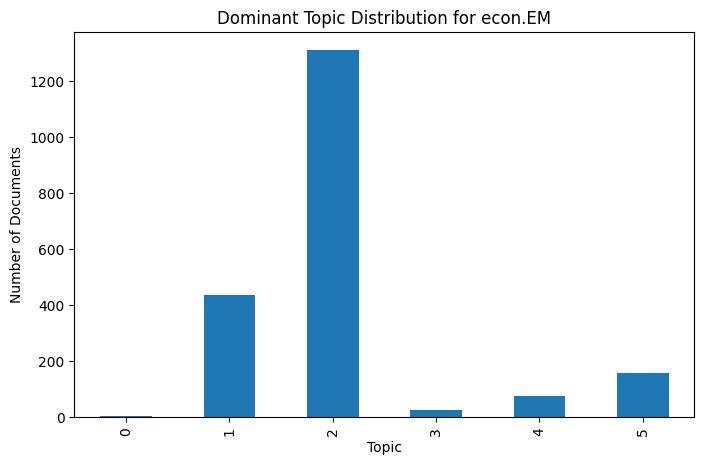

In [66]:
topic_dist = cat_df["dominant_topic"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
topic_dist.plot(kind="bar")
plt.xlabel("Topic")
plt.ylabel("Number of Documents")
plt.title(f"Dominant Topic Distribution for {selected_category}")
plt.show()

## Inspect Sample Documents for Each Topic

Topic keywords alone may not fully capture the meaning of each topic. Therefore, sample abstracts are reviewed for each dominant topic to validate whether the grouping is coherent and interpretable.

In [67]:
for topic_id in sorted(cat_df["dominant_topic"].unique()):
    print("=" * 80)
    print(f"TOPIC {topic_id}")
    print("=" * 80)

    topic_samples = cat_df[cat_df["dominant_topic"] == topic_id]["abstract"].head(3).tolist()

    for i, sample in enumerate(topic_samples, 1):
        print(f"\nSample {i}:")
        print(sample[:700])
        print()

TOPIC 0

Sample 1:
In many applications, the parameter of interest involves a simplex-valued weight which is identified as a solution to an optimization problem. Examples include synthetic control methods with group-level weights and various methods of model averaging and forecast combinations. The simplex constraint on the weight poses a challenge in statistical inference due to the constraint potentially binding. In this paper, we propose a simple method of constructing a confidence set for the weight using an adaptive test based on the projection on a polyhedral cone and prove that the method is asymptotically uniformly valid. The procedure does not require tuning parameters or simulations to compute critic


Sample 2:
Accurate forecasting of downside risks to economic growth is critically important for policymakers and financial institutions, particularly in the wake of recent economic crises. This paper extends the Growth-at-Risk (GaR) approach by introducing a novel daily sentime

## Compare Unigram, Bigram, and Trigram Representations

To justify the phrase modelling choice, we compare coherence scores across unigram-only, bigram-enhanced, and trigram-enhanced representations.

This helps determine whether trigrams provide real improvement or merely increase sparsity.

In [68]:
def evaluate_representation(docs, num_topics):
    dictionary = Dictionary(docs)
    dictionary.filter_extremes(no_below=5, no_above=0.5)
    corpus = [dictionary.doc2bow(doc) for doc in docs]

    lda_model = LdaModel(
        corpus=corpus,
        id2word=dictionary,
        num_topics=num_topics,
        random_state=42,
        chunksize=100,
        passes=10,
        alpha="auto"
    )

    coherence_model = CoherenceModel(
        model=lda_model,
        texts=docs,
        dictionary=dictionary,
        coherence="c_v"
    )

    return coherence_model.get_coherence()


comparison = pd.DataFrame({
    "representation": ["unigram", "bigram", "trigram"],
    "coherence": [
        evaluate_representation(cat_docs, best_result["num_topics"]),
        evaluate_representation(docs_bigram, best_result["num_topics"]),
        evaluate_representation(docs_trigram, best_result["num_topics"])
    ]
})

comparison

,representation,coherence
0,unigram,0.417361
1,bigram,0.354538
2,trigram,0.352591


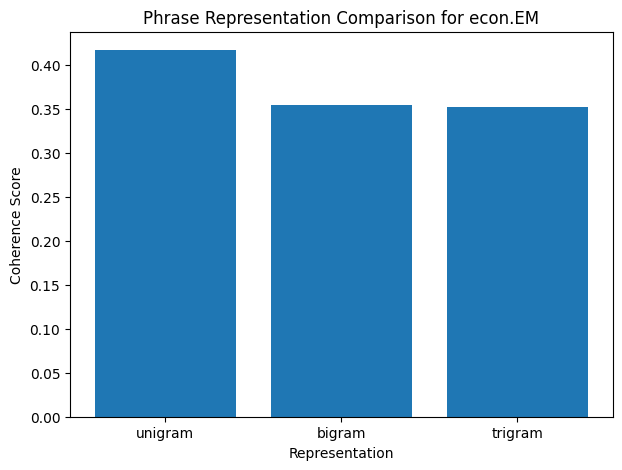

In [69]:
plt.figure(figsize=(7, 5))
plt.bar(comparison["representation"], comparison["coherence"])
plt.xlabel("Representation")
plt.ylabel("Coherence Score")
plt.title(f"Phrase Representation Comparison for {selected_category}")
plt.show()

#check if no of topic=4/5 is better
#check topic results for bigram and trigram
#topic visualiation 
#repeat for different category, saved results